# MASHeart: a step-by-step research workflow
**Question + scientific statement → stance → multi-agent review → evidence gate → evaluated output.**

This English notebook covers data setup, visualization, group splitting, actual training, validation,
frozen test evaluation, errors, uncertainty, saved models and new-input inference. Its reusable code is
the same `masheart/` package used by the command-line pipeline.

**Task boundary:** `YS` means the supplied statement affirms the supplied research question.
`NO` includes negation and lack of affirmation. These are text-stance labels, not clinical truth labels.
Task B is introduced only as a lexical illustration; its benchmark is not trained or evaluated here.

**Run on Colab:** upload this notebook, select a T4 GPU for QLoRA/MAS, and run in order. The source code,
attributed data, and configuration are embedded, so no parent repository, API key, or Drive mount is
required. The base model needs an Internet download on first use. CPU baseline steps run without a GPU.
T4 training/full MAS can take longer than a lesson: prepare the measured run before presenting it.

The embedded data originate with Alamri & Stevenson (2016), with official split alignment from
Kim, Rahimi & Allan's BioClaim (2023). Preserve the supplied provenance and data license notices.

## Step 01: Restore the standalone project

**Input:** an embedded ZIP containing English Python modules, configuration, source data and license notices.
**Output:** `PROJECT_ROOT`, independent of the original research repository.
SHA-256 verifies byte identity; safe path checks keep every extracted file inside the runtime folder.
The long Base64 string is transport, not a learned model. Existing project files are used when opened
inside a complete MASHeart folder; the embedded copy makes a single uploaded notebook sufficient.

In [1]:
#@title Restore the verified MASHeart source/data bundle (collapse this technical cell)
ASSET_BASE64 = '...'
ASSET_SHA256 = '74675a45c395ef07b14257fc4bc5a0efa2abdd85e05155f3ff67db11908abfd6'
ASSET_FILES = {'configs/cpu.json': 'a71a4c63b8d44d38757b322b2c8fd79521311abb58f5dd728af27eb509e09e1e', 'configs/t4.json': '60a74ac9e275bd23dc8b850b432ad9abe697176bf19ec3b5d8da1bae604681c5', 'data/DATA_CARD.md': '46a4808ea035837c4aa8790a4dffbc3c2766d515747cc3c9da2d900eb1c0e324', 'data/manifest.json': '066a7905db66023fcd525aafecd91c552b0db955ad183661edcaec90888b92e1', 'data/raw/a_dev.jsonl': '289ec05d947a7f14463ee3508d57c57354f7c770580eb0b6cfebb31c051d10fa', 'data/raw/a_test.jsonl': '211d7e686ab3d7eb16a67a5e1d2e899c6fede10f3631b61cf827ad17c520230c', 'data/raw/bioclaim_source_provenance.json': '5ec8116fdd98e2cbd4aca01b5244b20d4722769e13a675772e995311e5873d5d', 'data/raw/pcc_source_provenance.json': 'a3bfdaa091938b51ad21866d6c4207418a2e70adb006aa9b2c2867942ad59311', 'data/raw/source_split_manifest.json': '661d86dcad76b5ba617a1d2b57c5a3d93843ef3e5123bf23b69a168ca7d516c0', 'LICENSE_DATA.md': 'dcc9a97c841aa1656757f15b1ef072452f787db11c4b90e1ce9ce4e08c437a3e', 'masheart/__init__.py': '1f26213d7e7052f4348ea6ced9541d13e369bba03c7d8a99bb08924de3868f70', 'masheart/__main__.py': 'a657f1e95cee82e003f657d739544ac112b3dd8618801a648c20bf1c3ab43e90', 'masheart/baseline.py': '97c8f27a60bb131638ca8ab34aa7b3f82f7fc277b185c72544e5e9c08e9e4b98', 'masheart/cli.py': 'b7c1474fe6f0c6b852b0a5221c1da334c22f93fdbae85713a7a4b33469ae9b6a', 'masheart/data.py': '561d01b6b95d49784b7bbea55b0bb11915db6f3101de3ddd9390c57be2569e9a', 'masheart/experiment.py': '9fe31066b2dacd9f90c407123755297b7c24b22dbe31e10327d71a773b3aca7b', 'masheart/gpu.py': '1c54524f2f9178d9de9712d90bd856383d91e5fb48b6ba30b4153d423a1e1ab4', 'masheart/metrics.py': '5bed4b4a20fed40966ebbd9be2d4157d9e5d656fbb873f04e825656406730e86', 'masheart/visualization.py': '7e61c66d3667109dde29964dd9605470fcfa8c1035d9eef8dee049ce5f308623', 'requirements-t4.txt': '6e81265ccbbb3d20f975444c2d1f2ace62fa984b109c7155a1a8a70d31c4d65b', 'requirements.txt': '5ad13c5c88e2cd254921260ffbe73f68aa44723f5296981825258f23b986f779'}

import base64, hashlib, io, json, sys, zipfile
from pathlib import Path

candidates = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next((p for p in candidates if (p / 'masheart' / 'data.py').is_file()
                     and (p / 'data' / 'manifest.json').is_file()), None)
if PROJECT_ROOT is None:
    raw_archive = base64.b64decode(ASSET_BASE64)
    assert hashlib.sha256(raw_archive).hexdigest() == ASSET_SHA256
    PROJECT_ROOT = Path.cwd() / ('MASHeart_runtime_' + ASSET_SHA256[:10])
    PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(io.BytesIO(raw_archive)) as archive:
        for member in archive.infolist():
            target = (PROJECT_ROOT / member.filename).resolve()
            if not target.is_relative_to(PROJECT_ROOT.resolve()) or member.filename not in ASSET_FILES:
                raise ValueError('Unexpected archive path; extraction stopped.')
            content = archive.read(member)
            assert hashlib.sha256(content).hexdigest() == ASSET_FILES[member.filename]
            if target.exists() and target.read_bytes() != content:
                raise RuntimeError('An embedded source file was changed. Use a fresh runtime directory.')
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(content)
PROJECT_ROOT = PROJECT_ROOT.resolve()
sys.path.insert(0, str(PROJECT_ROOT))
print('Project:', PROJECT_ROOT)
print('No parent HeartMAS checkout is required.')


Project: C:\Users\huynh\OneDrive\Máy tính\ThsHUIT\HeartMAS\MASHeart\.verification\MASHeart_Step_by_Step_runtime\MASHeart_runtime_74675a45c3
No parent HeartMAS checkout is required.


## Step 02: Install the measured CPU environment

`importlib.metadata.version()` reads actual installed versions. The supplied requirements record the
reference environment. Only missing/different packages are installed. If an older module is already in
memory, restart after installation; pip cannot replace objects already imported into a kernel.
The local verification host already has these packages and performs no installation or network request.

In [2]:
import importlib.metadata, importlib.util, subprocess

required = {}
for line in (PROJECT_ROOT / 'requirements.txt').read_text().splitlines():
    if line.strip() and not line.startswith('#'):
        name, version = line.strip().split('==')
        required[name] = version
needed, loaded_changes = [], []
for name, version in required.items():
    try:
        installed = importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        needed.append(name + '==' + version)
        module = 'sklearn' if name == 'scikit-learn' else name
        if module in sys.modules:
            loaded_changes.append(module)
if needed:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *needed])
if loaded_changes:
    raise RuntimeError('Packages were updated after import: restart the kernel and run from the top.')
print({name: importlib.metadata.version(name) for name in required})


{'numpy': '2.2.6', 'pandas': '2.2.3', 'scipy': '1.14.1', 'scikit-learn': '1.5.2', 'matplotlib': '3.9.2', 'joblib': '1.4.2'}


## Step 03: Import shared code and fix the research configuration

`SEED=17` controls group randomization; it is not a guarantee of identical GPU arithmetic.
`RUN_DIR` creates a new experiment directory and protects existing results. The code records the
environment rather than assuming that equal seeds prove identical outputs on every machine.

In [3]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import masheart
from masheart.data import (verify_sources, load_frame, split_development, assert_disjoint,
                           public_payload, compose_text)
from masheart.baseline import make_classifier, make_dummy_classifier
from masheart.metrics import evaluate, paired_cluster_bootstrap
from IPython.display import display, Image

assert Path(masheart.__file__).resolve().is_relative_to(PROJECT_ROOT)
DATA_DIR = PROJECT_ROOT / 'data'
CPU_CONFIG = json.loads((PROJECT_ROOT / 'configs' / 'cpu.json').read_text())
SEED = CPU_CONFIG['seed']
LABELS = ['NO', 'YS']
RUN_DIR = PROJECT_ROOT / 'runs' / ('notebook_' + str(time.time_ns()))
RUN_DIR.mkdir(parents=True, exist_ok=False)
np.random.seed(SEED)
print('New run:', RUN_DIR)


New run: C:\Users\huynh\OneDrive\Máy tính\ThsHUIT\HeartMAS\MASHeart\.verification\MASHeart_Step_by_Step_runtime\MASHeart_runtime_74675a45c3\runs\notebook_1794720703444101100


## Step 04: Verify data and read development only

`verify_sources()` checks manifest paths, byte counts and SHA-256 without parsing test labels.
`load_frame(..., 'dev')` reads UTF-8 JSONL and validates schema, ID uniqueness and labels.
Preserve question/text source strings for quoting. Do not remove negation, numbers or conditions.
The original release has no independent train set: this project uses educational development fitting.

In [4]:
source_audit = verify_sources(DATA_DIR)
dev = load_frame(DATA_DIR / 'raw' / 'a_dev.jsonl', 'dev')
assert len(dev) == 125 and dev.group_id.nunique() == 11
display(dev[['id', 'question', 'text', 'label', 'group_id']].head(3))
display(dev.label.value_counts().reindex(LABELS).rename('examples').to_frame())
print('Verified source files:', source_audit['files_verified'])


,id,question,text,label,group_id
0,mc-23435582-00,"In women with pre-eclampsia, does treatment wi...",Supplementation during pregnancy with a medica...,YS,qg-23435582
1,mc-23435582-01,"In women with pre-eclampsia, does treatment wi...",Oral L-arginine supplementation did not reduce...,NO,qg-23435582
2,mc-23435582-02,"In women with pre-eclampsia, does treatment wi...",L-Arginine load in pregnant women is associate...,NO,qg-23435582


,examples
label,
NO,41
YS,84


Verified source files: 5


## Step 05: Visualize label balance and statement lengths

**Scientific display:** export the measured table as well as PNG/SVG. The label chart exposes class
imbalance; the histogram describes whitespace length, which differs from the model's subword tokens.
These plots summarize development only and do not select examples based on test scores.

In [5]:
development_profile = dev[['id', 'group_id', 'label']].copy()
development_profile['whitespace_words'] = dev.text.map(lambda value: len(value.split()))
development_profile.to_csv(RUN_DIR / 'development_profile.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
dev.label.value_counts().reindex(LABELS).plot.bar(ax=axes[0], color=['#c56c39', '#287da8'])
axes[0].set(title='Development label balance', xlabel='Stance', ylabel='Examples')
axes[0].tick_params(axis='x', rotation=0)
axes[1].hist(development_profile.whitespace_words, bins=10, color='#287da8', edgecolor='white')
axes[1].set(title='Statement length', xlabel='Whitespace words', ylabel='Examples')
fig.tight_layout()
fig.savefig(RUN_DIR / 'development_overview.png', dpi=200, bbox_inches='tight')
fig.savefig(RUN_DIR / 'development_overview.svg', bbox_inches='tight')
plt.show()


C:\Users\huynh\AppData\Local\Temp\ipykernel_10568\2565811707.py:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Step 06: Create group-disjoint training and validation

`validation_fraction=0.25` means a fraction of source groups, not exactly 25% of rows.
Whole linked groups remain together. For seed 17, development becomes 95 examples/8 groups for
training and 30 examples/3 groups for validation. `assert_disjoint()` also checks IDs, PMIDs and
normalized statements. The official test is not an input to this splitting function.

In [6]:
train, validation = split_development(dev, SEED, CPU_CONFIG['validation_fraction'])
split_audit = assert_disjoint(train, validation)
split_summary = pd.DataFrame([
    {'split': name, 'n': len(frame), 'groups': frame.group_id.nunique(),
     'NO': int(frame.label.eq('NO').sum()), 'YS': int(frame.label.eq('YS').sum())}
    for name, frame in [('train', train), ('validation', validation)]
])
display(split_summary)
split_summary.to_csv(RUN_DIR / 'development_split.csv', index=False)
assert len(train) == 95 and len(validation) == 30


,split,n,groups,NO,YS
0,train,95,8,32,63
1,validation,30,3,9,21


## Step 07: Protect the inference feature boundary

`public_payload()` returns question and text only. ID/group/PMID may be used to audit or join results,
while gold labels are used only for fitting or scoring. `compose_text()` prepares the same two fields
for the CPU classifier. Changing gold or metadata must not change the public model input.

In [7]:
example = train.iloc[0].to_dict()
modified = dict(example, label='NO' if example['label'] == 'YS' else 'YS', pmid='EXCLUDED')
assert public_payload(example) == public_payload(modified)
display(public_payload(example))
print(compose_text(example))


{'question': 'In women with pre-eclampsia, does treatment with L Arginine, compared to placebo, reduce blood pressure or pre-eclampsia',
 'text': 'Supplementation during pregnancy with a medical food containing L-arginine and antioxidant vitamins reduced the incidence of pre-eclampsia in a population at high risk of the condition.'}

Question: In women with pre-eclampsia, does treatment with L Arginine, compared to placebo, reduce blood pressure or pre-eclampsia
Statement: Supplementation during pregnancy with a medical food containing L-arginine and antioxidant vitamins reduced the incidence of pre-eclampsia in a population at high risk of the condition.


## Step 08: Understand TF-IDF before training

`fit_transform()` learns vocabulary and inverse-document frequency and transforms its input.
Later validation/test use only `transform()` inside the Pipeline. Word n-grams (1,2) retain features
such as `not reduce`; `stop_words=None` preserves negation. This small synthetic example is never
inserted into the real dataset. Smoothed IDF is `log((1+n)/(1+df))+1`, followed by vector normalization.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
toy = ['the trial reduced outcome', 'the trial did not reduce outcome',
       'the study reported another outcome']
toy_vectorizer = TfidfVectorizer(ngram_range=(1, 2), stop_words=None)
toy_values = toy_vectorizer.fit_transform(toy)
toy_table = pd.DataFrame(toy_values.toarray(), columns=toy_vectorizer.get_feature_names_out())
display(toy_table[['trial', 'outcome', 'not', 'not reduce']].round(3))


,trial,outcome,not,not reduce
0,0.345,0.268,0.000,0.000
1,0.256,0.198,0.336,0.336
2,0.000,0.213,0.000,0.000


## Step 09: Train two CPU controls on permitted training rows

`make_classifier()` builds two TF-IDF feature branches and **one** balanced logistic regression.
Word(1,2) and char_wb(3,5) are representations, not independent agents. C=1 controls inverse
regularization strength; max_iter=2000 limits optimizer iterations. `fit()` is actual training.
`make_dummy_classifier()` learns the training-majority class; it never inspects test label frequencies.

In [9]:
train_texts = [compose_text(row) for row in train.to_dict('records')]
validation_texts = [compose_text(row) for row in validation.to_dict('records')]
cpu_model = make_classifier({key: CPU_CONFIG[key] for key in ['C', 'max_iter', 'seed']})
majority_model = make_dummy_classifier()
started = time.perf_counter()
cpu_model.fit(train_texts, train.label)
majority_model.fit(np.zeros((len(train), 1)), train.label)
print('Training seconds:', round(time.perf_counter() - started, 3))
print('Classes:', cpu_model.classes_)
print('Features:', len(cpu_model['features'].get_feature_names_out()))


Training seconds: 0.291
Classes: ['NO' 'YS']
Features: 10639


## Step 10: Inspect learned weights and score validation

A coefficient describes a fitted association, not causality. `predict()` applies the trained model;
it does not refit TF-IDF. `evaluate()` keeps NO and YS in macro-F1 and retains INVALID as errors.
Precision asks how often a predicted class is correct; recall asks how much of a gold class is found.
Macro-F1 averages the two class F1 values equally. Probability-like classifier scores are uncalibrated.

In [10]:
names = cpu_model['features'].get_feature_names_out()
weights = cpu_model['classifier'].coef_[0]
order = np.argsort(weights)
display(pd.DataFrame({'feature': names[np.r_[order[:5], order[-5:]]],
                      'weight_toward_YS': weights[np.r_[order[:5], order[-5:]]]}))
validation_cpu = cpu_model.predict(validation_texts).tolist()
validation_majority = majority_model.predict(np.zeros((len(validation), 1))).tolist()
validation_metrics = pd.DataFrame([
    evaluate(validation.label, validation_majority, 'majority'),
    evaluate(validation.label, validation_cpu, 'tfidf_logreg')])
display(validation_metrics.round(4))
validation_metrics.to_csv(RUN_DIR / 'validation_metrics.csv', index=False)


,feature,weight_toward_YS
0,words__did,-0.431443
1,words__did not,-0.431443
2,words__not,-0.421357
3,words__no,-0.413466
4,words__polymorphism,-0.295994
5,words__that,0.193117
6,words__improve,0.195382
7,words__be,0.203535
8,words__may,0.235287
9,words__and,0.289830


,system,n,accuracy,macro_f1,valid_rate,invalid_count,precision_NO,recall_NO,f1_NO,support_NO,precision_YS,recall_YS,f1_YS,support_YS
0,majority,30,0.7000,0.4118,1.0,0,0.0,0.0000,0.0000,9,0.70,1.0000,0.8235,21
1,tfidf_logreg,30,0.7333,0.6273,1.0,0,0.6,0.3333,0.4286,9,0.76,0.9048,0.8261,21


### Optional T4 experiment: pretraining, QLoRA and role-based MAS
The base Qwen model already knows language from pretraining. QLoRA freezes its quantized base and
updates small rank-8 adapters on q/v projections. NF4 reduces weight storage; FP16 is the compute
type chosen for T4. Not all activation/optimizer memory is four-bit. The training target contains
**only** the supplied JSON stance label: no invented gold explanations are added.

All GPU steps below are guarded. In CPU mode, they describe the real implemented method and report
that no GPU run occurred. Parser/gate examples are explicitly synthetic logic checks, not scores.

## Step 11: Select GPU mode and install the pinned T4 stack

Colab users select Runtime → Change runtime type → T4 GPU. CUDA availability is checked rather than
assuming a Python import provides hardware. PyTorch/CUDA are kept as supplied by Colab.
The project pins Transformers/PEFT/accelerate/bitsandbytes. Restart when changing an imported package.

In [11]:
USE_T4 = False
if importlib.util.find_spec('torch') is not None:
    import torch
    USE_T4 = torch.cuda.is_available()
USE_T4 = USE_T4 and os.environ.get('MASHEART_CPU_ONLY') != '1'
if USE_T4:
    pins = {'transformers': '4.57.1', 'peft': '0.17.1',
            'accelerate': '1.10.1', 'bitsandbytes': '0.48.1'}
    for name, version in pins.items():
        if name in sys.modules and getattr(sys.modules[name], '__version__', None) != version:
            raise RuntimeError('Restart before changing an imported GPU library: ' + name)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                           *[name + '==' + value for name, value in pins.items()]])
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('CPU mode: no QLoRA training or LLM inference is claimed.')
from masheart.gpu import T4Runtime, encode_supervised, parse_packet, gate_packets
t4_config = json.loads((PROJECT_ROOT / 'configs' / 't4.json').read_text())
gpu_runtime = None


CPU mode: no QLoRA training or LLM inference is claimed.


## Step 12: Load the quantized model and inspect assistant-only loss masking

`load_model()` uses the pinned model revision, NF4, double quantization, FP16 and gradient checkpointing.
`encode_supervised()` returns token IDs, attention mask, and loss labels. Prompt positions get -100;
answer tokens and EOS contribute loss. Padding also gets -100, while attention padding gets 0.
Training context 512, inference input 1536 and new-output 192 are three different limits.

In [12]:
if USE_T4:
    gpu_runtime = T4Runtime(output_dir=RUN_DIR / 't4', config=t4_config)
    gpu_runtime.load_model()
    encoded = encode_supervised(train.iloc[0].to_dict(), gpu_runtime.tokenizer,
                                max_tokens=t4_config['max_train_tokens'])
    targets = [token for token in encoded['labels'] if token != -100]
    print('Input tokens:', len(encoded['input_ids']))
    print('Loss target:', gpu_runtime.tokenizer.decode(targets))
else:
    print('Read masheart/gpu.py: encode_supervised() and collate_examples().')


Read masheart/gpu.py: encode_supervised() and collate_examples().


## Step 13: Train QLoRA with a validation-selected checkpoint

Batch1 × accumulation 8 gives a nominal effective batch 8 on one GPU. Train 3 epochs with lr1e-4,
warmup 5%, gradient clipping 0.3 and checkpointing. The best checkpoint is selected by validation loss,
not by test. Prediction-loss-only evaluation avoids retaining enormous vocabulary logits.
Re-running this stage can be expensive; prepare the run before teaching. Loss is not 1−accuracy.

In [13]:
if USE_T4:
    gpu_runtime.train(train, validation)
    print('Adapter saved:', gpu_runtime.adapter_dir)
    print('Training seconds:', gpu_runtime.training_seconds)
else:
    print('Training not executed: no CUDA device.')


Training not executed: no CUDA device.


## Step 14: Compare pretrained and fine-tuned modes on validation

The adapter checkpoint is chosen by validation loss. Then compare generated labels from base and
adapter on the same 30 validation rows: select the adapter only if its macro-F1 is strictly higher;
ties retain base. Fine-tuning can hurt on 95 examples. Reviewer/Verifier always use the base instruct
model via disable_adapter, so the label-only adapter does not suppress their structured review.

In [14]:
if USE_T4:
    gpu_validation = gpu_runtime.validate_and_select(validation)
    display(pd.DataFrame(gpu_validation).round(4))
    print('Analyst uses adapter:', gpu_runtime.analyst_use_adapter)
else:
    print('No pretrained/fine-tuned performance measurements exist for this CPU notebook run.')


No pretrained/fine-tuned performance measurements exist for this CPU notebook run.


## Step 15: Understand the exact-source evidence gate

`parse_packet()` separates schema validity from quote validity. Reviewer/Verifier quotes must occur
exactly once and unchanged in the source, with a nonempty rationale. A sourced quote is a provenance
check, not proof of correct meaning. `gate_packets()` accepts a changed valid draft only when both
later agents agree on the new label and have valid source quotes; otherwise it keeps the draft and
marks review. An invalid draft may be repaired by a sourced final, still with a review flag.

In [15]:
synthetic_source = {'question': 'Does X reduce outcome Y?',
                    'text': 'The synthetic study did not reduce outcome Y.'}
synthetic_generation = {'status': 'ok', 'raw': json.dumps(
    {'label': 'NO', 'quote': 'an invented quote', 'rationale': 'A synthetic test.'})}
checked = parse_packet(synthetic_generation, synthetic_source, require_quote=True)
assert not checked['quote_valid']
initial = {'label': 'YS', 'schema_valid': True, 'quote_valid': False}
review = {'label': 'NO', 'schema_valid': True, 'quote_valid': False}
final = {'label': 'NO', 'schema_valid': True, 'quote_valid': True}
blocked = gate_packets(initial, review, final)
assert blocked['label'] == 'YS'
display({'synthetic_logic_check_only': True, 'gate': blocked})


{'synthetic_logic_check_only': True,
 'gate': {'label': 'YS',
  'review': True,
  'gate_status': 'blocked_revision_or_invalid_final'}}

## Step 16: Freeze the method before loading test labels

Save configuration, training/validation IDs, source audit and trained CPU hash. The T4 protocol also
freezes prompts, revision, mode, adapter and implementation. MAS uses Analyst → Reviewer → Verifier;
these are role prompts using one base checkpoint, not independently trained specialist doctors.

In [16]:
frozen_cpu_hash = joblib.hash(cpu_model)
frozen = {'config': CPU_CONFIG, 'train_ids': train.id.tolist(),
          'validation_ids': validation.id.tolist(), 'cpu_hash': frozen_cpu_hash,
          'source_audit': source_audit, 'gpu_executed': USE_T4}
(RUN_DIR / 'notebook_frozen_protocol.json').write_text(json.dumps(frozen, indent=2))
if USE_T4:
    gpu_runtime.freeze_protocol(source_audit)
    validation_traces = gpu_runtime.run_split(validation, 'notebook_validation')
    print(json.dumps(validation_traces[0], indent=2))
print('CPU hash:', frozen_cpu_hash)


CPU hash: b2c2571b7c8367704a4f8bd1bdfa72d2


## Step 17: Load the preserved official test and predict every row

Test is loaded after freezing. Test input always passes through public_payload/compose_text; gold is
attached only for scoring. The protocol preserves all 134 official examples and10 source groups.
The original project has prior development/test exposure: this is not a historically pristine holdout.

In [17]:
test = load_frame(DATA_DIR / 'raw' / 'a_test.jsonl', 'test')
assert_disjoint(train, test)
assert_disjoint(validation, test)
assert joblib.hash(cpu_model) == frozen_cpu_hash
test_texts = [compose_text(row) for row in test.to_dict('records')]
cpu_predictions = cpu_model.predict(test_texts).tolist()
majority_predictions = majority_model.predict(np.zeros((len(test), 1))).tolist()
predictions = test[['id', 'group_id', 'question', 'text', 'label']].rename(columns={'label': 'gold'}).copy()
predictions['majority'] = majority_predictions
predictions['tfidf_logreg'] = cpu_predictions
metrics = [evaluate(test.label, majority_predictions, 'majority'),
           evaluate(test.label, cpu_predictions, 'tfidf_logreg')]
print('Complete test rows:', len(predictions))
assert len(predictions) == 134 and predictions.id.is_unique


Complete test rows: 134


## Step 18: Execute the full three-stage MAS test when T4 is available

`run_split()` records every raw response, parsed packet, decision, failure, token count and elapsed time.
Protocol/input-bound JSONL checkpoints support continuation without silently retrying failed examples.
`direct_label` is the draft from the same trace: Direct costs one model step, MAS normally three.
Keep INVALID in the denominator. Compare complete 134-row outputs, not a few selected examples.

In [18]:
llm_records = []
if USE_T4:
    llm_records = gpu_runtime.run_split(test, 'notebook_test')
    assert len(llm_records) == len(test)
    predictions['direct'] = [record['direct_label'] for record in llm_records]
    predictions['mas'] = [record['label'] for record in llm_records]
    predictions['review'] = [record['review'] for record in llm_records]
    metrics += [evaluate(test.label, predictions.direct, 'qwen_direct'),
                evaluate(test.label, predictions.mas, 'qwen_mas')]
else:
    print('LLM test not run; no GPU scores are filled in.')
metric_table = pd.DataFrame(metrics)
display(metric_table.round(4))


LLM test not run; no GPU scores are filled in.


,system,n,accuracy,macro_f1,valid_rate,invalid_count,precision_NO,recall_NO,f1_NO,support_NO,precision_YS,recall_YS,f1_YS,support_YS
0,majority,134,0.7164,0.4174,1.0,0,0.0000,0.0000,0.0000,38,0.7164,1.0000,0.8348,96
1,tfidf_logreg,134,0.7388,0.5629,1.0,0,0.6364,0.1842,0.2857,38,0.7480,0.9583,0.8402,96


## Step 19: Read confusion matrices and per-class recall

Rows are gold; columns are predictions. Add INVALID to the matrix when needed so failures remain
visible. A majority predictor can have high accuracy and zero NO recall. Always read macro-F1,
class support and per-class results alongside accuracy.

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report
column = 'mas' if USE_T4 else 'tfidf_logreg'
order = LABELS + (['INVALID'] if 'INVALID' in predictions[column].tolist() else [])
matrix = confusion_matrix(test.label, predictions[column], labels=order)
ConfusionMatrixDisplay(matrix, display_labels=order).plot(cmap='Blues', colorbar=False)
plt.title('Complete official test: ' + column)
plt.tight_layout(); plt.show()
print(classification_report(test.label, predictions[column], labels=LABELS, zero_division=0))


              precision    recall  f1-score   support

          NO       0.64      0.18      0.29        38
          YS       0.75      0.96      0.84        96

    accuracy                           0.74       134
   macro avg       0.69      0.57      0.56       134
weighted avg       0.72      0.74      0.68       134



C:\Users\huynh\AppData\Local\Temp\ipykernel_10568\3058133935.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


## Step 20: Measure selective coverage and computational cost

A review flag does not erase a prediction from complete-test metrics. Coverage is the fraction not
flagged for review. Compare Direct and MAS on exactly the same accepted subset, and show its size.
Token/time measurements come from the stored generations, not from a fixed assumed call count.

In [20]:
if USE_T4:
    mask = ~predictions.review.astype(bool)
    print('Coverage:', float(mask.mean()), '| accepted:', int(mask.sum()), '/', len(mask))
    if mask.any():
        display(pd.DataFrame([evaluate(test.label[mask], predictions[name][mask], name)
                              for name in ['direct', 'mas']]).round(4))
    cost_rows = []
    for record in llm_records:
        for call in record['trace']:
            generation = call['generation']
            cost_rows.append({'role': call['role'], 'seconds': generation['elapsed_seconds'],
                              'calls': generation['model_calls'],
                              'input_tokens': generation['input_tokens'],
                              'output_tokens': generation['output_tokens']})
    display(pd.DataFrame(cost_rows).groupby('role').sum().round(3))
else:
    print('GPU coverage/cost cannot be measured from CPU controls.')


GPU coverage/cost cannot be measured from CPU controls.


## Step 21: Export actual GPU training and review figures

When a real T4 run exists, export its assistant-token train/validation loss, full-test metrics,
confusion matrix, measured cost and beneficial/harmful review outcomes. Every figure includes PNG,
SVG, a source CSV and a hash manifest. CPU logic checks cannot supply any of these GPU measurements.

In [21]:
if USE_T4:
    from masheart.gpu import generate_gpu_figures
    gpu_test_metrics = [row for row in metrics if row['system'] in ['qwen_direct', 'qwen_mas']]
    gpu_figures = generate_gpu_figures(gpu_runtime.output_dir, test, llm_records, gpu_test_metrics)
    print('Measured GPU figure types:', len(gpu_figures['figures']))
    for path in sorted((gpu_runtime.output_dir / 'figures').glob('*.png')):
        display(Image(filename=str(path)))
else:
    print('No GPU figures are fabricated for a CPU-only run.')


No GPU figures are fabricated for a CPU-only run.


## Step 22: Inspect errors and estimate uncertainty by source group

Read the full question, statement and conditions before interpreting an error. Do not tune on test
after seeing these errors. Paired cluster bootstrap resamples complete source groups, applies the
same selected rows to both systems, and reports macro-F1(B)−macro-F1(A). With only 10 groups, the
percentile interval is uncertain and is not a clinical guarantee or automatic evidence of superiority.

In [22]:
column_a, column_b = ('direct', 'mas') if USE_T4 else ('majority', 'tfidf_logreg')
errors = predictions[predictions.gold.ne(predictions[column_b])]
with pd.option_context('display.max_colwidth', 180):
    display(errors[['question', 'text', 'gold', column_b]].head(5))
bootstrap = paired_cluster_bootstrap(test.label, predictions[column_a], predictions[column_b],
                                      test.group_id, rounds=CPU_CONFIG['bootstrap_rounds'], seed=SEED)
print(column_b, '-', column_a, '| CI95:', bootstrap['ci_lower'], bootstrap['ci_upper'])
plt.hist(bootstrap['differences'], bins=25, color='#287da8', edgecolor='white')
plt.axvline(0, color='black', linestyle='--')
plt.xlabel('Paired cluster bootstrap macro-F1 difference'); plt.ylabel('Draws')
plt.tight_layout(); plt.show()


,question,text,gold,tfidf_logreg
0,"In patients with coronary artery disease (CAD), is C242T polymorphism of P22(PHOX) gene associated in development of CAD",The present study suggests a protective association between the c.-930A>G promoter polymorphism in the p22-PHOX (CYBA) gene and the development of myocardial infarction in youn...,YS,NO
2,"In patients with coronary artery disease (CAD), is C242T polymorphism of P22(PHOX) gene associated in development of CAD","Our observations indicate a significant relationship between p22phox C242T and PARP-1 Val762Ala polymorphisms, CAD and its severity, but not with occurrence of MI in T2DM indiv...",YS,NO
9,"In patients with coronary artery disease (CAD), is C242T polymorphism of P22(PHOX) gene associated in development of CAD",The ecNOS gene a/b polymorphism and the NADH/NADPH oxidase p22 phox gene C242T polymorphism were found to be significantly associated with the development of CAD in Korean male...,YS,NO
10,"In patients with coronary artery disease (CAD), is C242T polymorphism of P22(PHOX) gene associated in development of CAD",The C242T variant was associated with CHD risk in women.,YS,NO
12,"In patients with coronary artery disease (CAD), is C242T polymorphism of P22(PHOX) gene associated in development of CAD",In the total population and in high and low risk groups the relative frequencies of the C242T alleles were essentially the same in patients without or with CAD and in individua...,NO,YS


tfidf_logreg - majority | CI95: 0.0 0.2416057707568053


C:\Users\huynh\AppData\Local\Temp\ipykernel_10568\3301250675.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


## Step 23: Save and reload the model and measured outputs

Persist the Pipeline, CSV predictions, metrics, split and environment. Check a validation roundtrip;
serialization is not another training stage. Adapters alone do not include all 4B base weights.

In [23]:
model_path = RUN_DIR / 'notebook_tfidf_logreg.joblib'
joblib.dump(cpu_model, model_path)
restored = joblib.load(model_path)
assert restored.predict(validation_texts).tolist() == validation_cpu
assert joblib.hash(cpu_model) == frozen_cpu_hash
predictions.to_csv(RUN_DIR / 'notebook_test_predictions.csv', index=False)
metric_table.to_csv(RUN_DIR / 'notebook_test_metrics.csv', index=False)
print('Saved model:', model_path)


Saved model: C:\Users\huynh\OneDrive\Máy tính\ThsHUIT\HeartMAS\MASHeart\.verification\MASHeart_Step_by_Step_runtime\MASHeart_runtime_74675a45c3\runs\notebook_1794720703444101100\notebook_tfidf_logreg.joblib


## Step 24: Generate the canonical reproducible research artifact set

The command-line experiment is the same fixed CPU method implemented in reusable functions. Run it
once here to export the full scientific artifact set: eight PNG/SVG figure pairs, their exact CSV
inputs, validation/test tables, saved models, source/split audits, frozen hashes, environment,
complete manifest and a research report. This is a repeatability exercise with unchanged settings,
not a fresh held-out assessment or a new round of test-driven model selection.

,system,n,accuracy,macro_f1,valid_rate,invalid_count,precision_NO,recall_NO,f1_NO,support_NO,precision_YS,recall_YS,f1_YS,support_YS
0,majority,134,0.7164,0.4174,1.0,0,0.0000,0.0000,0.0000,38,0.7164,1.0000,0.8348,96
1,tfidf_logreg,134,0.7388,0.5629,1.0,0,0.6364,0.1842,0.2857,38,0.7480,0.9583,0.8402,96


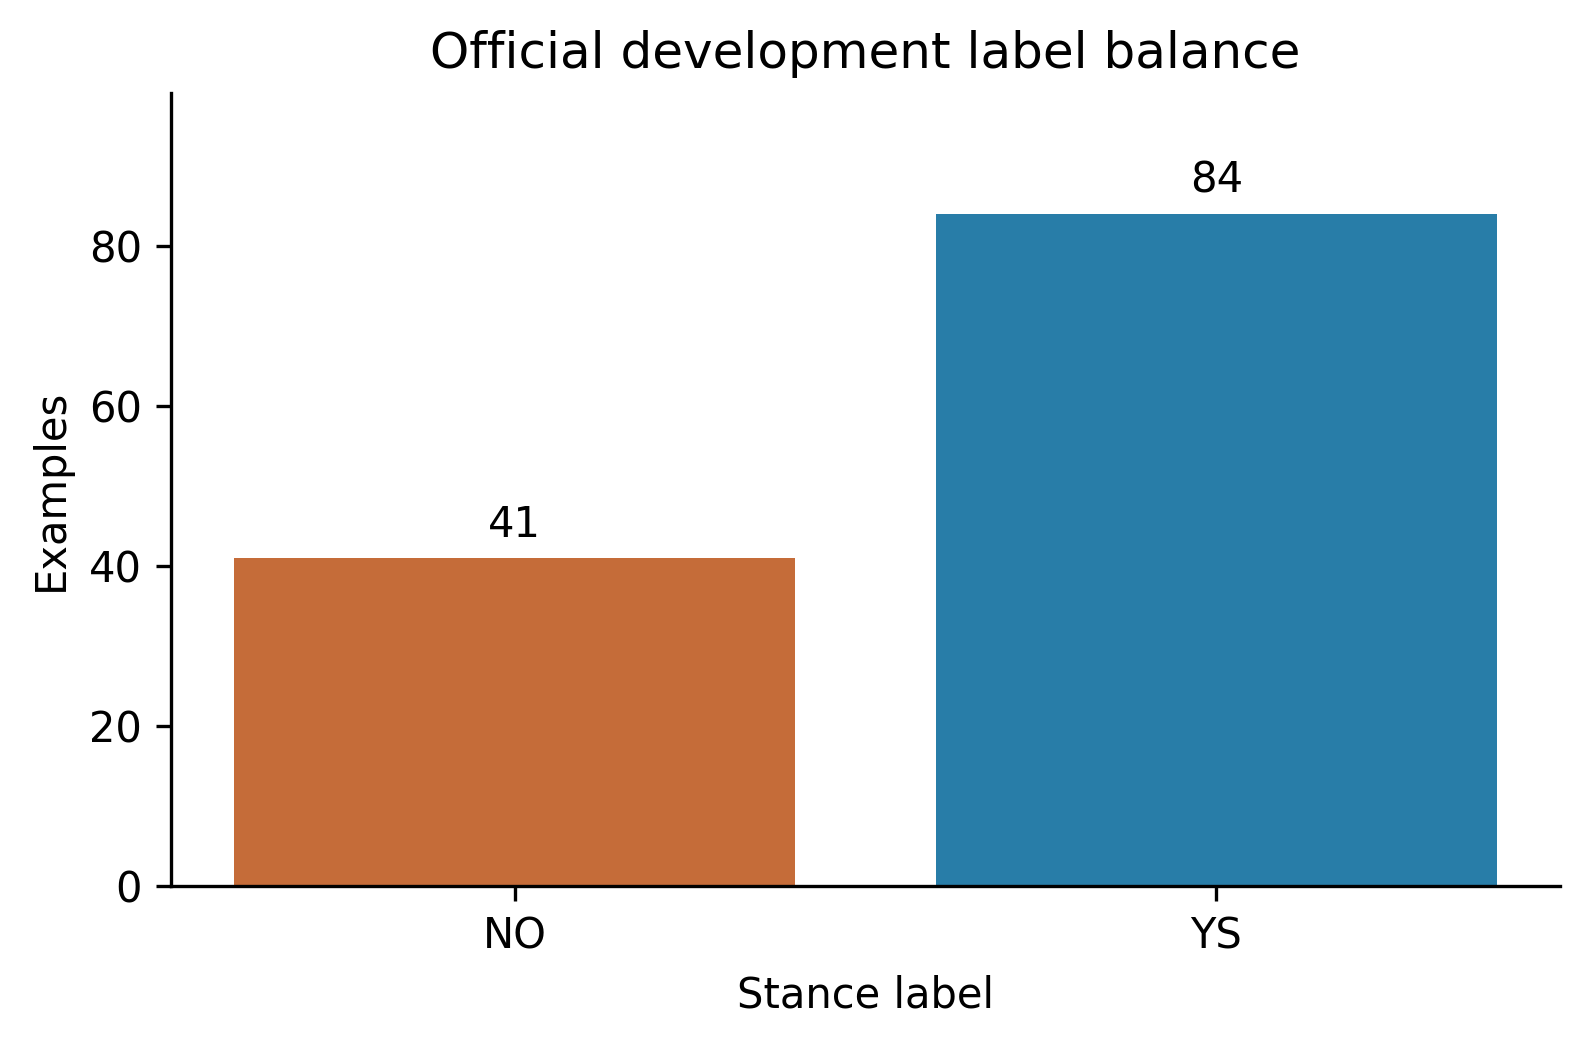

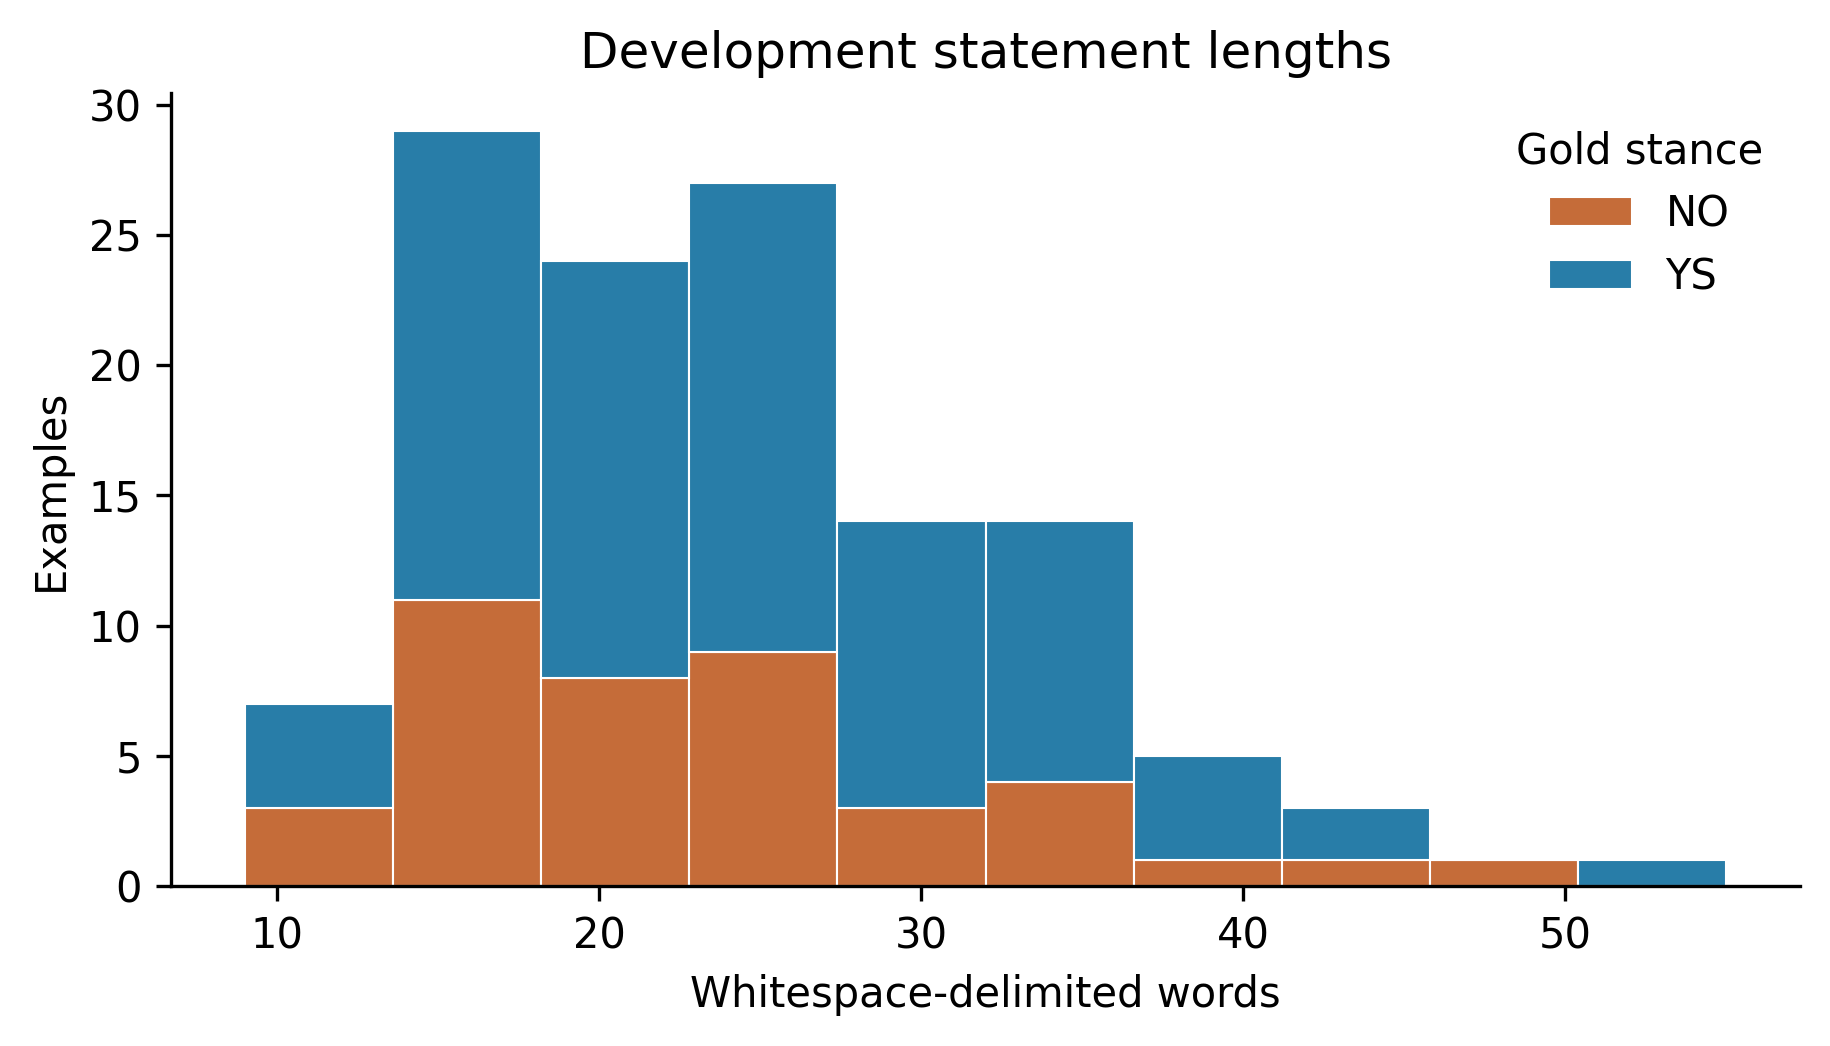

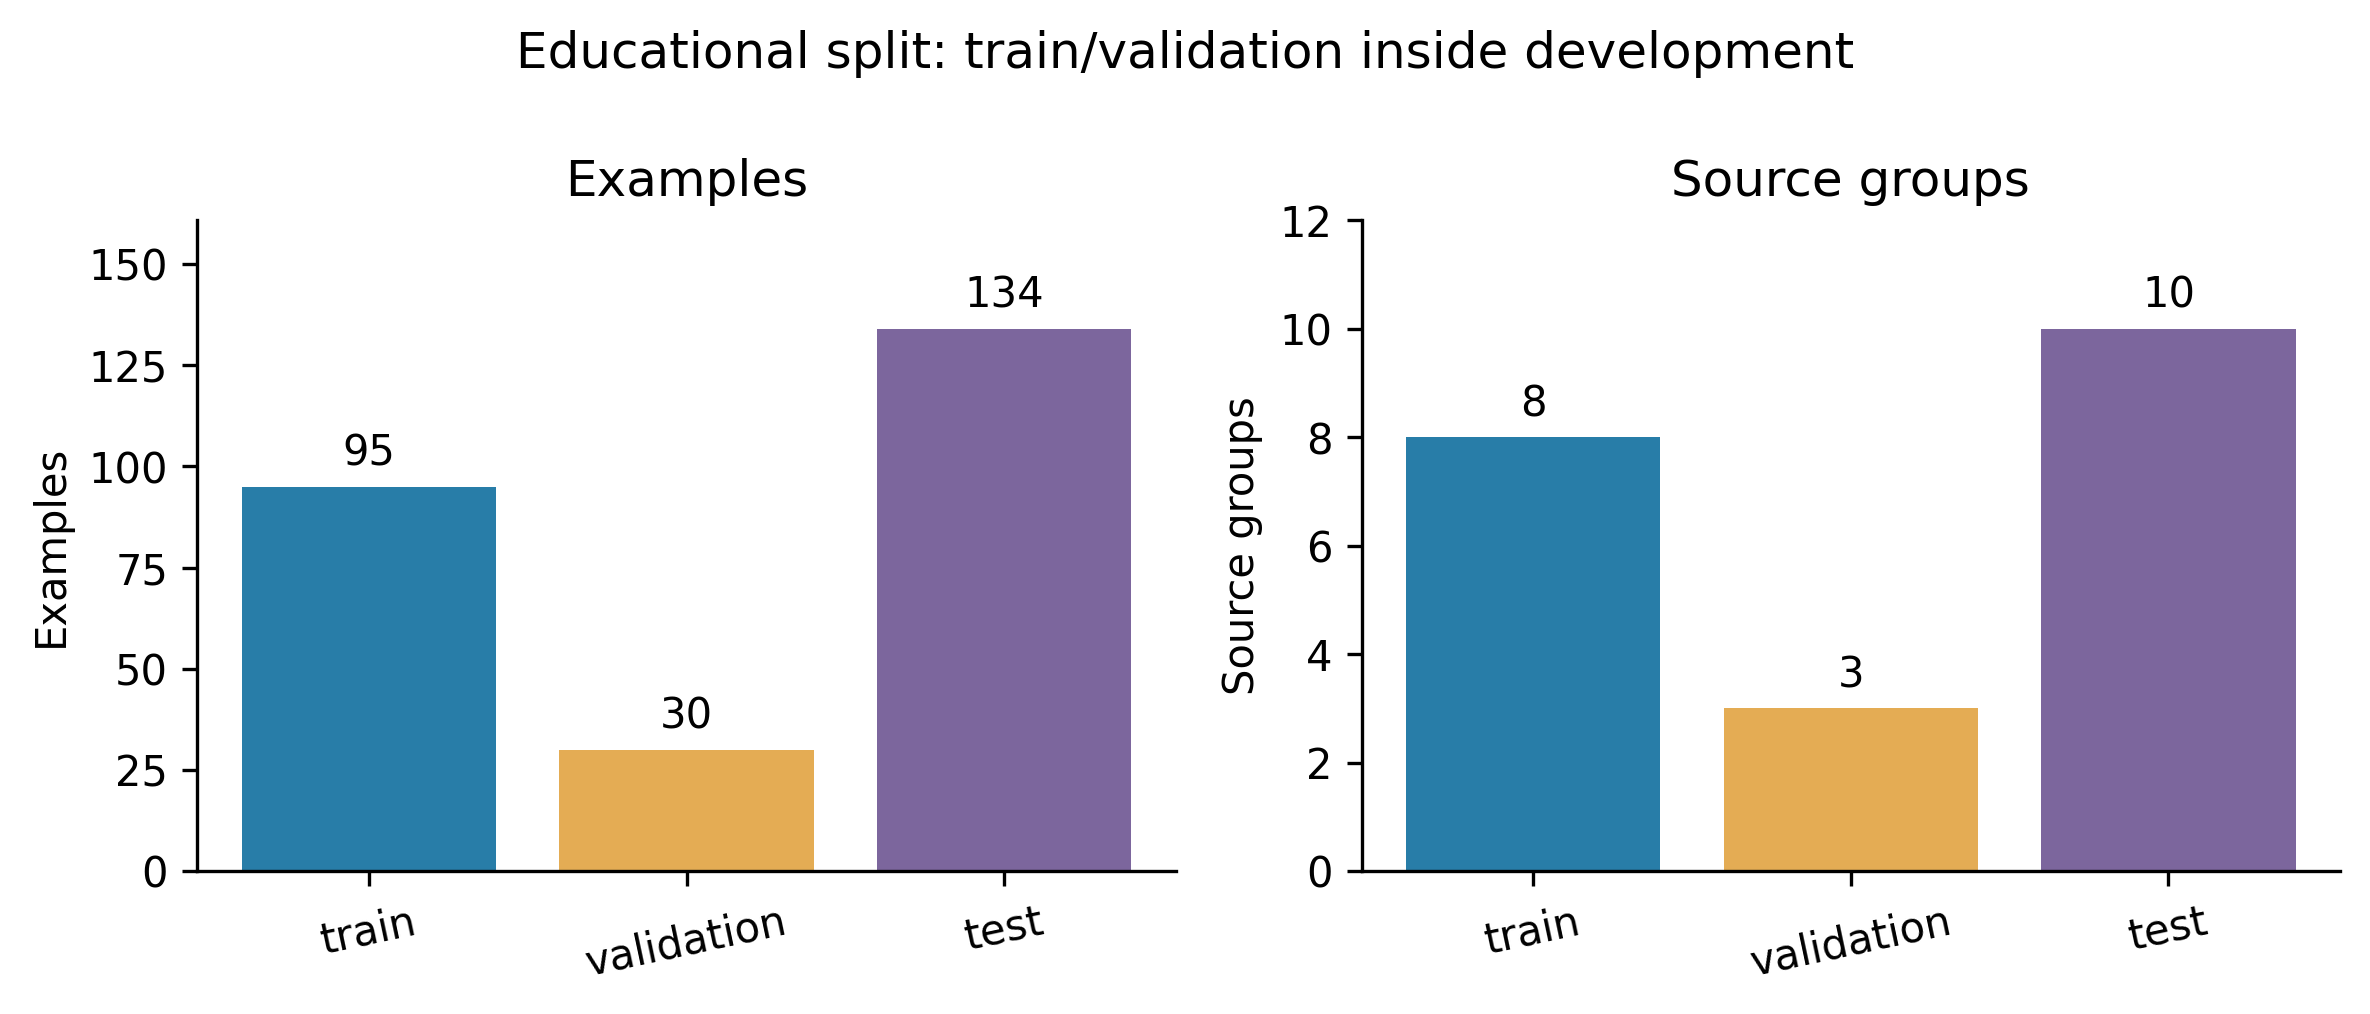

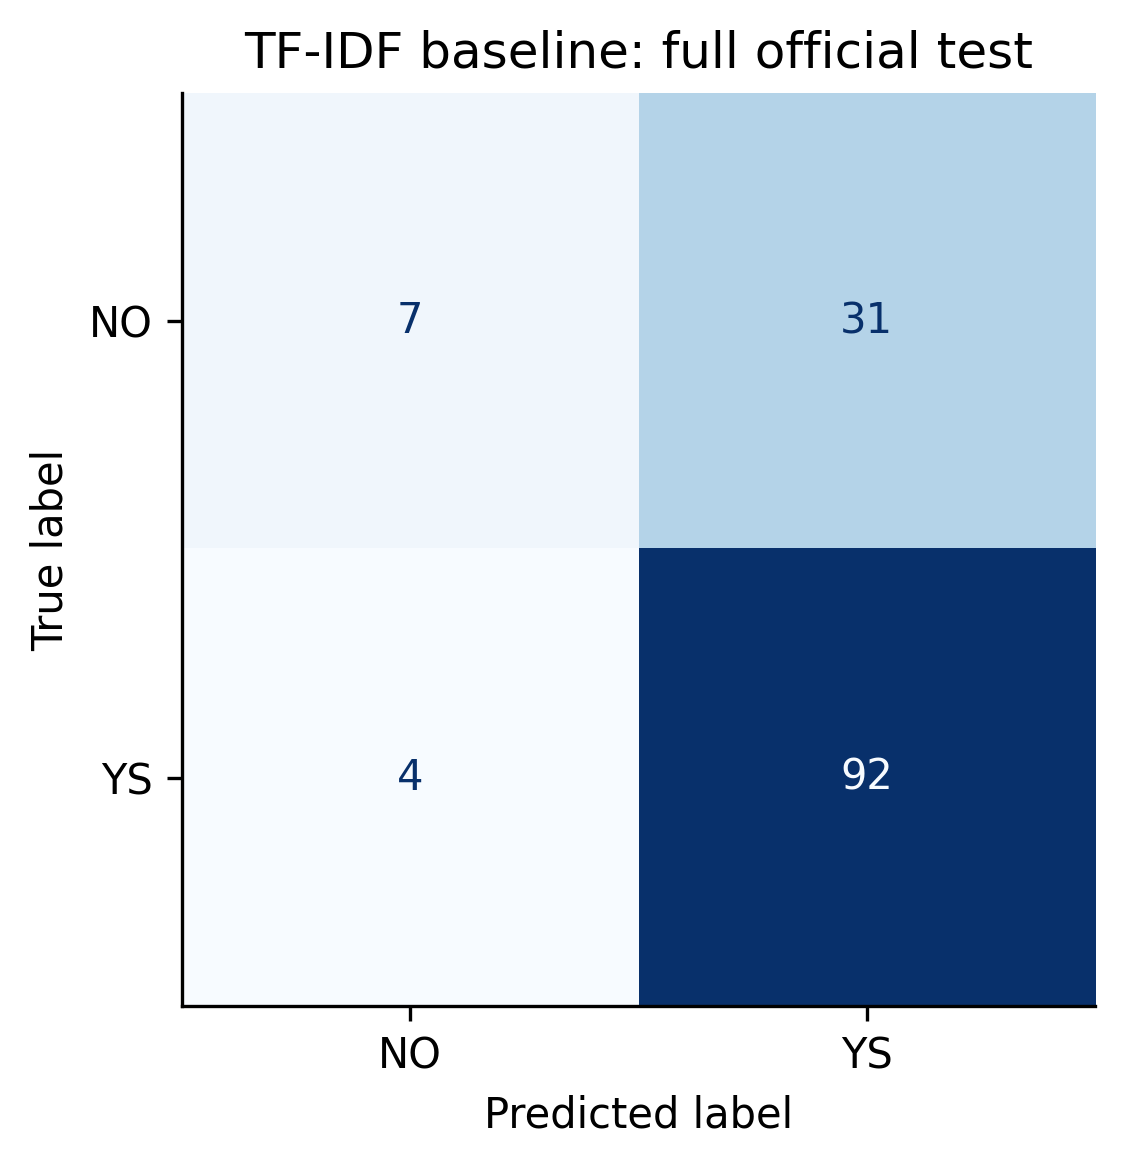

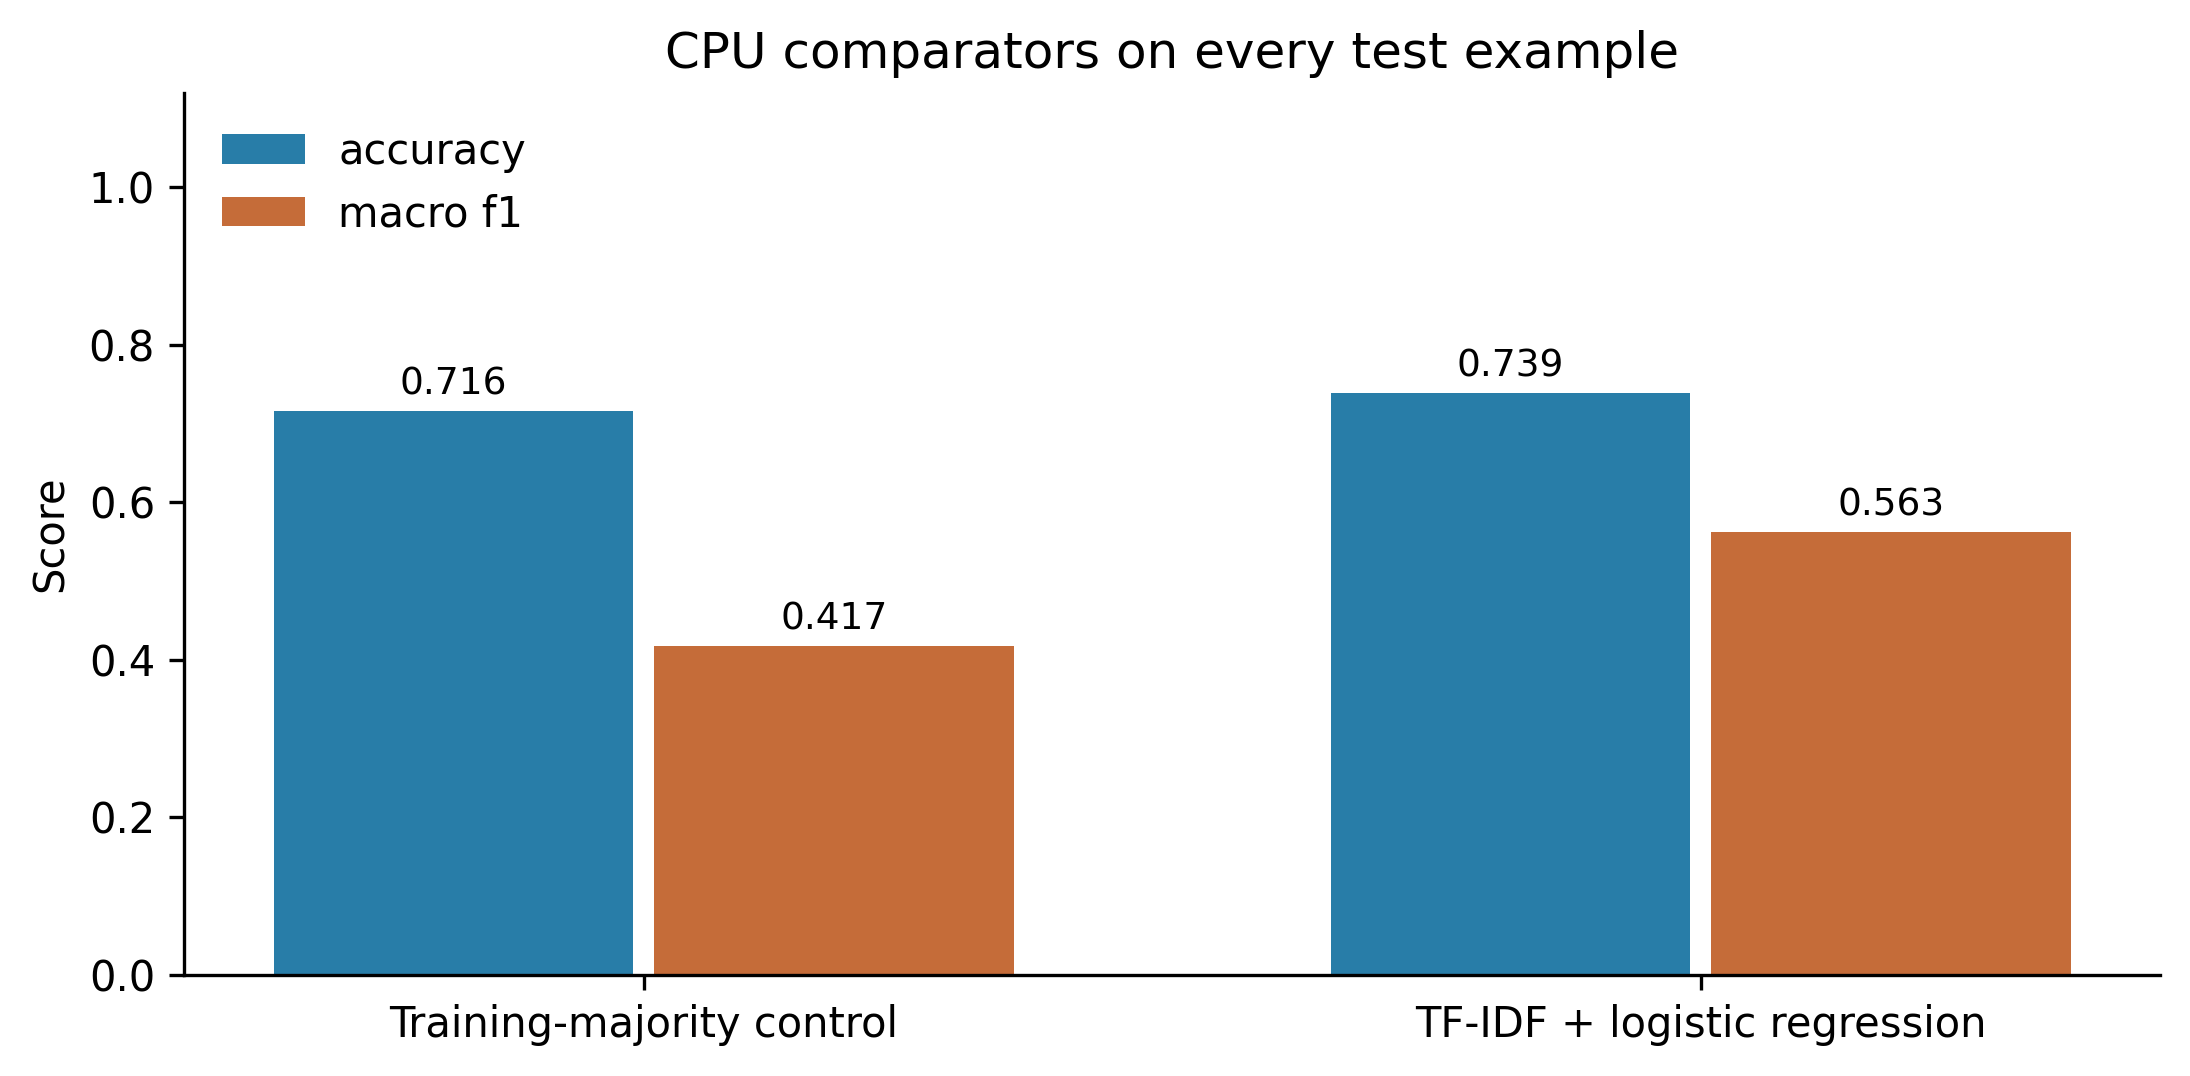

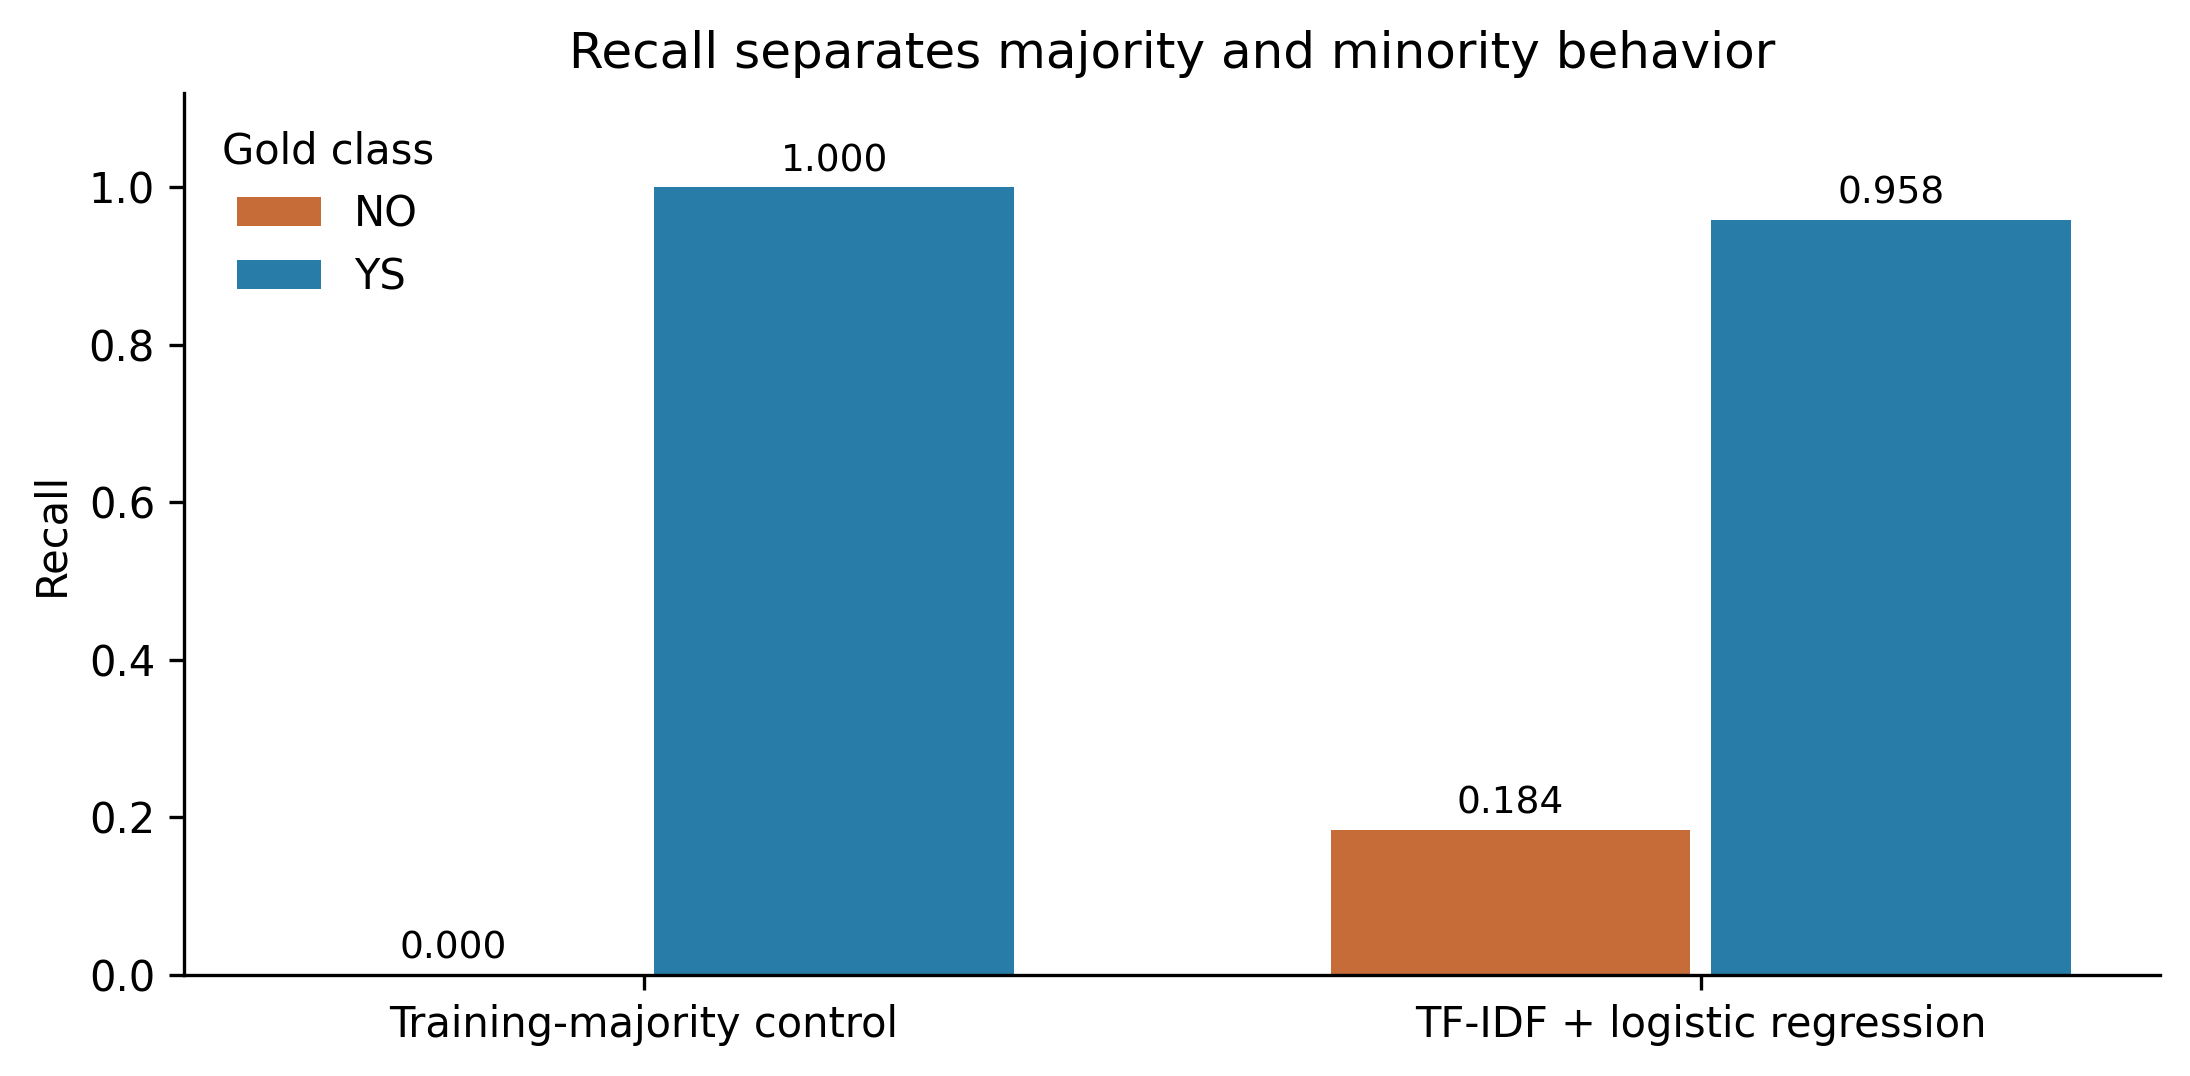

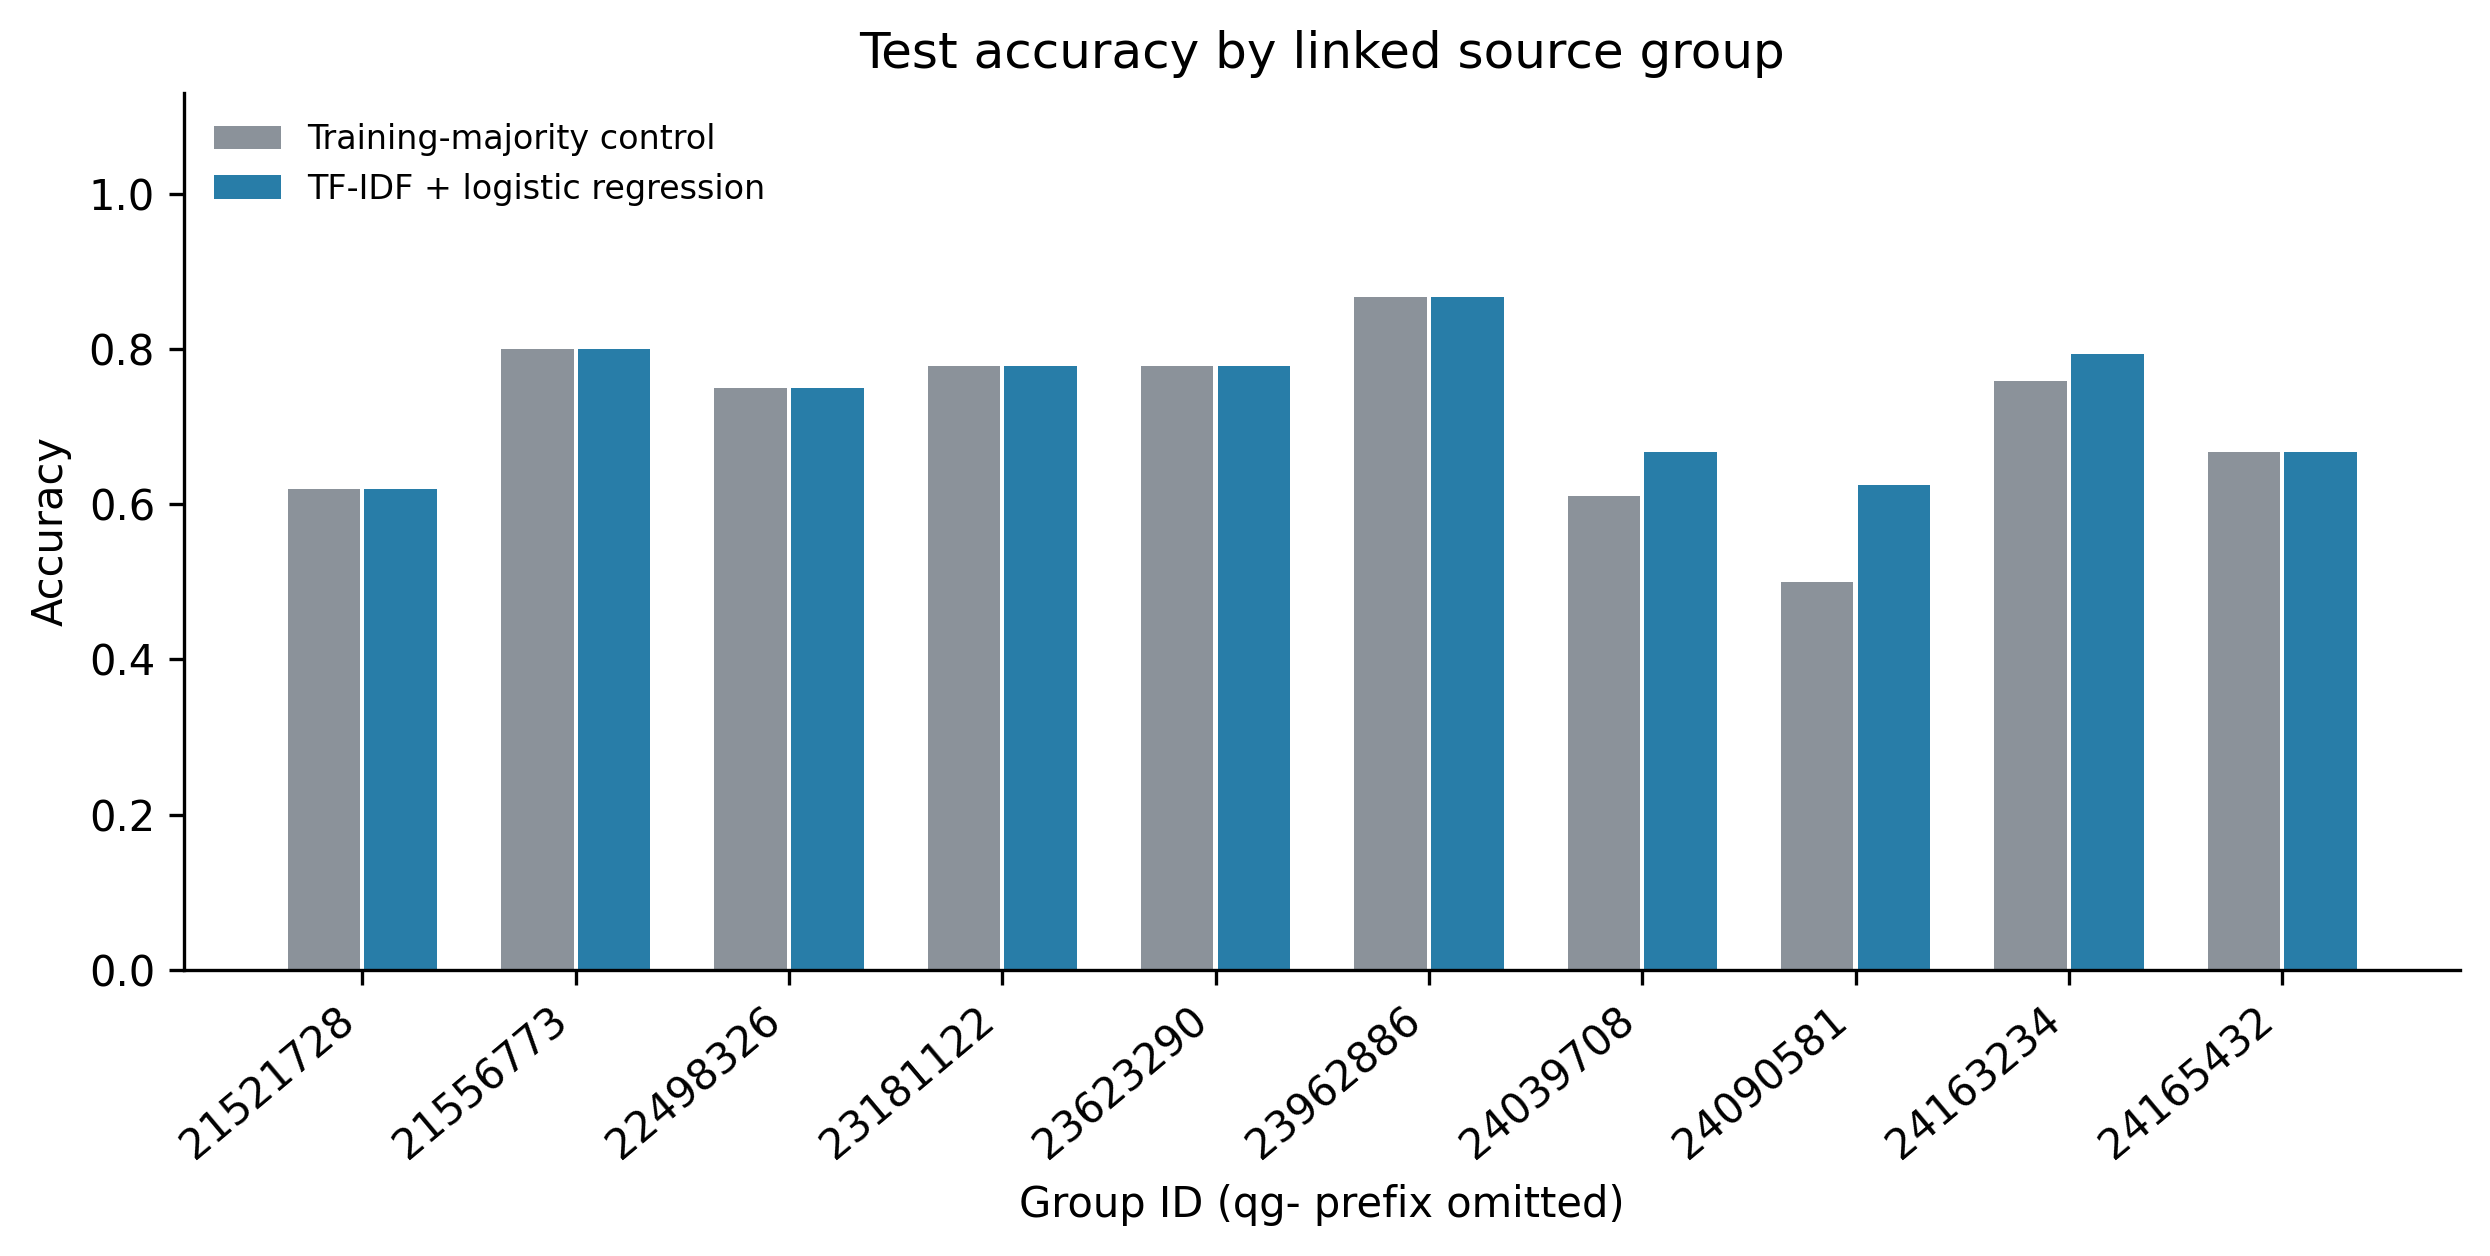

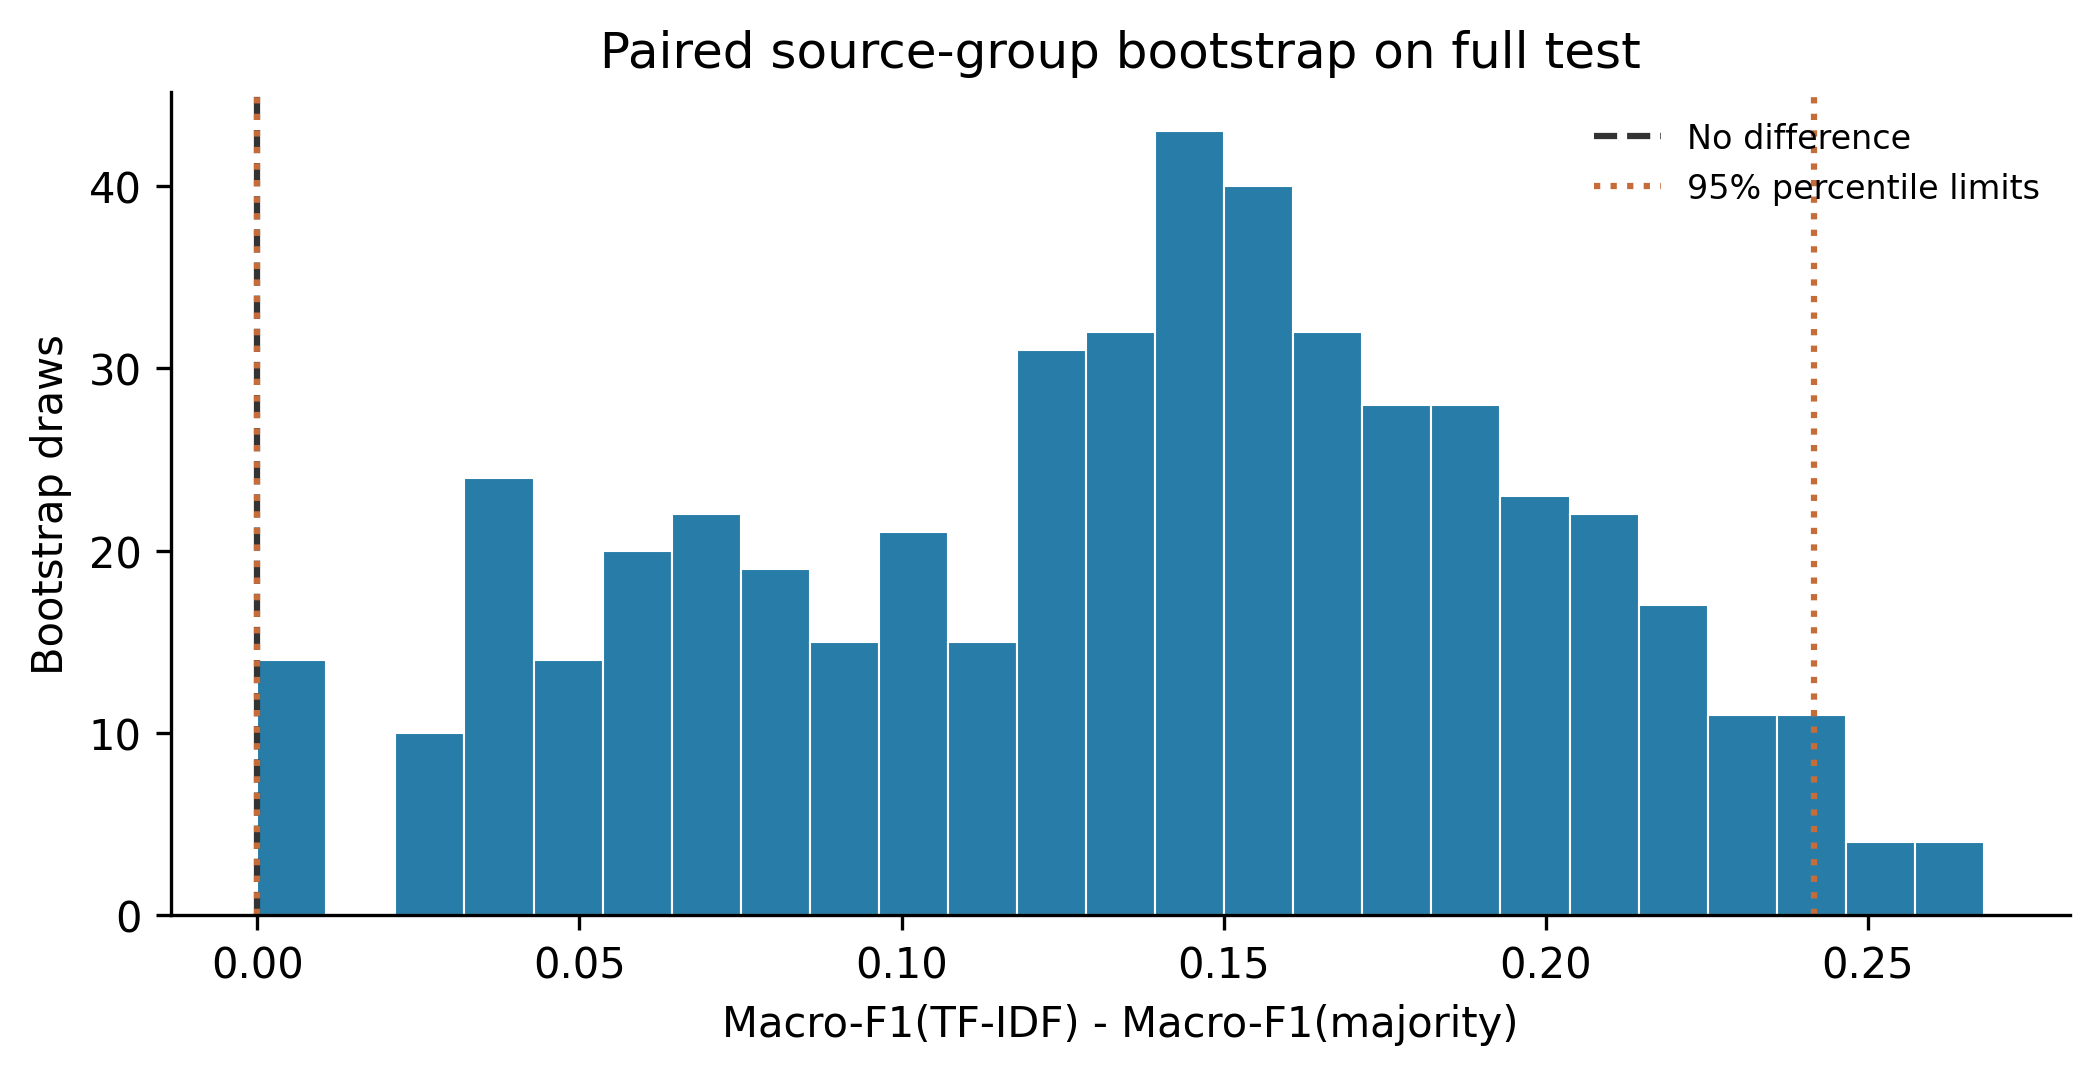

# MASHeart CPU research report

This report records an executed educational Task-A experiment. It predicts the stance of a supplied English statement toward a supplied research question. YS means affirmation; NO means negation or lack of affirmation. Neither label establishes clinical truth, diagnostic accuracy or treatment quality.

## Data and protocol

PCC statements and stance labels originate with Abdulaziz Alamri and Mark Stevenson (2016). Official development/test membership follows the linked BioClaim release preserved in the data manifest. The original release has no independent training set. This run uses 95 training examples in 8 groups and 30 validation examples in 3 groups, both drawn only from official development; all 134 official test examples in 10 groups are retained.

The training and validation split is by linked source group with seed 17. ID, group, PMID and normalized-statement intersections are empty across these partitions and test. The complete source audit and

In [24]:
from masheart.experiment import run_cpu_experiment
research_run = RUN_DIR / 'cpu_research'
research_summary = run_cpu_experiment(DATA_DIR, research_run, CPU_CONFIG)
canonical_predictions = pd.read_csv(research_run / 'tables' / 'test_predictions.csv')
assert canonical_predictions.tfidf_logreg.tolist() == cpu_predictions
display(pd.read_csv(research_run / 'tables' / 'test_metrics.csv').round(4))
for path in sorted((research_run / 'figures').glob('*.png')):
    display(Image(filename=str(path)))
print((research_run / 'reports' / 'CPU_RESEARCH_REPORT.md').read_text())


## Step 25: Test a new synthetic statement and export your run

A new interactive input has no independently supplied gold, so do not report accuracy from one demo.
The English synthetic example is for language behavior, not treatment advice. Task B can be explored
by comparing surface tokens, but lexical difference is not a semantic contradiction annotation.
Download the result ZIP before a temporary Colab runtime is reclaimed.

In [25]:
new_source = {'question': 'Does treatment X reduce blood pressure compared with placebo?',
              'text': 'The synthetic trial did not find a reduction after eight weeks compared with placebo.'}
if USE_T4:
    print(json.dumps(gpu_runtime.run_mas(new_source), indent=2))
else:
    print({'system': 'CPU control', 'label': restored.predict([compose_text(new_source)])[0]})
import shutil
export_path = shutil.make_archive(str(RUN_DIR), 'zip', root_dir=RUN_DIR)
print('Result ZIP:', export_path)
DOWNLOAD_RESULTS = False
if DOWNLOAD_RESULTS:
    from google.colab import files
    files.download(export_path)


{'system': 'CPU control', 'label': 'YS'}
Result ZIP: C:\Users\huynh\OneDrive\Máy tính\ThsHUIT\HeartMAS\MASHeart\.verification\MASHeart_Step_by_Step_runtime\MASHeart_runtime_74675a45c3\runs\notebook_1794720703444101100.zip


## Research questions and reporting checklist
1. Why does a statement about a different outcome receive NO even without the word `not`?
2. Which operations fit parameters, and which merely transform or validate data?
3. Why can a majority classifier look accurate while missing every minority-class example?
4. Did fine-tuning improve validation? Did the extra MAS calls improve complete-test results?
5. How often did the evidence gate block or allow a change? Can sourced quotes still be misinterpreted?
6. What are the number of source groups, confidence interval, failures, coverage and computational cost?

Report measured results, source history and limitations. The packaged CPU reference is a real run;
the GPU status file is `not_run` until an actual T4 experiment is performed.

Primary references: [PCC (2016)](https://doi.org/10.1186/s13326-016-0083-z),
[Cond-NLI/BioClaim (2023)](https://aclanthology.org/2023.findings-emnlp.456/),
[Qwen model card](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507),
[Trainer 4.57.1](https://huggingface.co/docs/transformers/v4.57.1/en/main_classes/trainer),
[PEFT quantization](https://huggingface.co/docs/peft/v0.17.0/en/developer_guides/quantization).